# How to sample constrained densities?

Sampling constrained densities is commonly encountered in Bayesian inference for dynamical systems, when parameters have to meet conservation laws or represent other physical quantities. Formally, we are intersted in sampling a probability density restricted to a feasible set $\newcommand{\K}{\mathcal{K}}\K$, i.e.
$$
\newcommand{\xx}{\boldsymbol{x}}\newcommand{\yy}{\boldsymbol{y}}p(\xx) \propto \tilde{p}(\xx) \cdot 1_{\xx \in \K}
$$
with $\tilde{p}$ some possibly unconstrained density. While such a problem can be sampled using an off-the-shelf Metropolis-Hastings algortihm given it is started inside $\K$ --- since the rejection will take care of an infeasible proposals --- this turns out to be very inefficient, especially as dimension grows. Thus, specialized sampling algorithms have been developed to incorporate constraints and generate more informed proposals.

These samplers typically leverage the fact that 
$$
    \K := \left\{ \xx \in \mathbb{R}^d : c(\xx) \leq 0 \right\}
$$ 
is defined by a set of "simple" constraint functions $c: \mathbb{R}^d \to \mathbb{R}^m$, like linear or quadratic functions.

In this notebook, we showcase tools and sampling algorithms to work with constraints. 

In [1]:
import numpy as np

import jax
import jax.numpy as jnp
import blackjax

import matplotlib.pyplot as plt

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


## Uniform sampling

If $\K$ has finite Lebesgue measure, the uniform density on $\K$ is well-defined. In this case $\tilde{p}=\mathrm{const}$.

We start by considering an ellipsoidal set
$$
    \K_{\mathrm{ell}} := \{ \xx \in \mathbb{R}^d : \xx^\top M \xx - 1 \leq 0 \}
$$
with 
$$
    M = \begin{pmatrix}
        2 & 1 \\
        1 & 1 
    \end{pmatrix}
$$

Some of the constrained sampling algorithms handle different types constraints in different manners in order to efficiently compute Hessians of the constraint functions or find intersections of randomized directions with the borders of $\K$. Thus, the ellipsoidal constraint gets defined by a wrapper object marking the ellipsoidal constraint as such. We can visualize this 2-dimensional constraint as follows

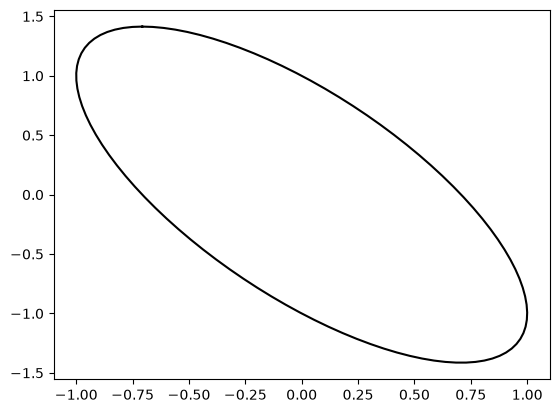

In [2]:
M = np.array([[2, 1], [1, 1]])
ellipsoidal_constraint = blackjax.mcmc.constraints.ellipsoid_constraint(M, jnp.array([0, 0]))

# Plotting
c = np.linspace(0, 2*np.pi, 100)
c = np.array([np.sin(c), np.cos(c)])
L = np.linalg.cholesky(M)
e = np.linalg.solve(L.T, c)
plt.plot(e[0], e[1], color='black')
plt.show()

In order to sample the uniform density, we define a constant unnormalized densityon $\K$. For this, we use the helper function `blackjax.mcmc.constraints.constrain(logp, constraint)`.

In [3]:
logp = blackjax.mcmc.constraints.constrain(lambda x: 0., ellipsoidal_constraint)

Using MALA here boils down to a Gaussian random-walk MH algorithm, since the gradient of the constant density is zero almost everywhere.

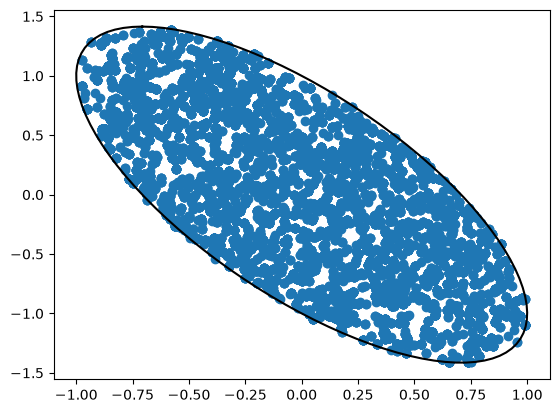

In [4]:
mala = blackjax.mala(logp, 1e0)

state = mala.init(np.zeros(2))
step = jax.jit(mala.step)

def one_step(step, s, k):
    s_new, _ = step(k, s)
    return s_new, s_new

keys = jax.random.split(jax.random.key(42), 10000)
_, states = jax.lax.scan(lambda s, k: one_step(step, s, k), state, keys)
x = states.position

plt.scatter(x[:,0], x[:,1])
plt.plot(e[0], e[1], color='black')
plt.show()

Alternatively, we can use constraint samping algorithms such as elliptical Hit-&-Run or the Dikin walk. Hit-&-Run works by decomposing the proposal into two steps: First drawing a random direction, then drawing the step along that direction from a univariate, truncated distribution, such that the resulting proposal is guaranteed to be feasible. Dikin walk preconditions a Gaussian random-walk proposal with the inverse Hessain of the log-barrier function to mitigate proposing infeasible proposals.

In order to construct these transition kernels such that they respect the constraint, the constraints have to be passed at construction explicitly.

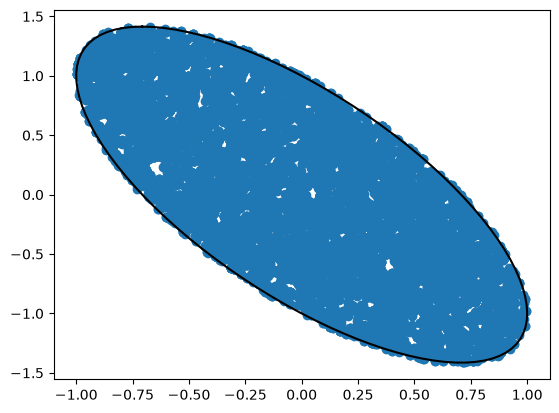

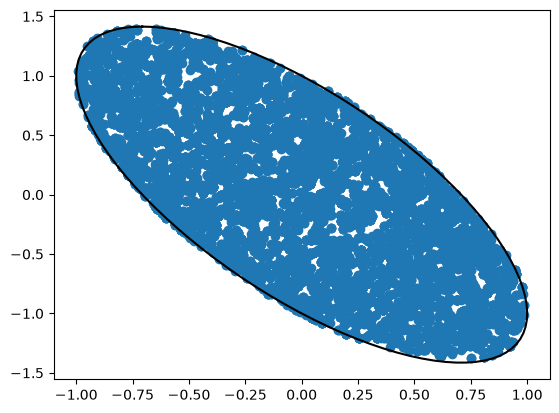

In [5]:
for sampler in [blackjax.hr, blackjax.dikin]:
    mc = sampler(logp, ellipsoidal_constraint, 1e0)

    state = mc.init(np.zeros(2))
    step = jax.jit(mc.step)

    keys = jax.random.split(jax.random.key(42), 10000)
    _, states = jax.lax.scan(lambda s, k: one_step(step, s, k), state, keys)
    x = states.position

    plt.scatter(x[:,0], x[:,1])
    plt.plot(e[0], e[1], color='black')
    plt.show()

## Combining constraints

Similar to the ellipsoidal constraints before, we can also define linear constraints. In the following example, these form a simplex, i.e.
$$
    \K_{\mathrm{sim}} = \left\{ \xx \in \mathbb{R}^d : b - Ax \leq 0 \right\}
$$
with 
$$
    A = \begin{pmatrix}
        1 & 1 \\
        -1 & 0 \\
        0 & -1
    \end{pmatrix} \text{ and }
    b = \begin{pmatrix}
        1 \\
        0 \\
        0
    \end{pmatrix}.
$$

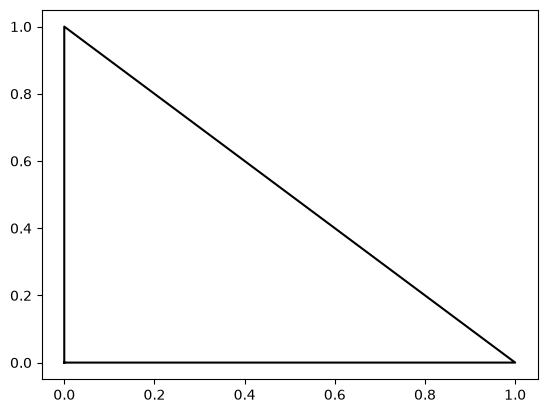

In [6]:
A, b = np.array([[1, 1], [-1, 0], [0, -1]]), np.array([1, 0, 0])
simplex_constraint = blackjax.mcmc.constraints.LinearConstraint(A, b)

plt.plot([0, 0, 1, 0], [0, 1, 0, 0], color='black')
plt.show()

These constraints get combined into a `blackjax.mcmc.constraints.ComposedConstraint`. As before, we then constraint a constant unnormalized density with these constraints and sample away.

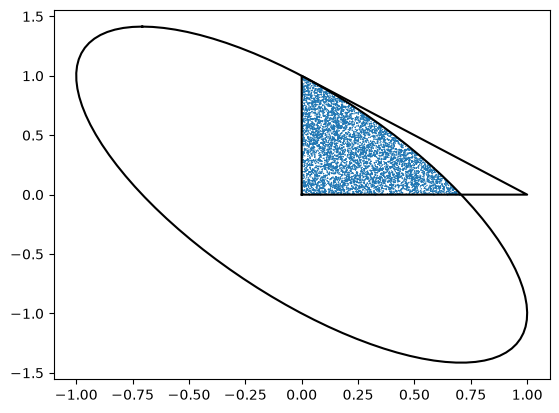

In [7]:
combined_constraint = blackjax.mcmc.constraints.ComposedConstraint([simplex_constraint, ellipsoidal_constraint])
logp = blackjax.mcmc.constraints.constrain(lambda x: 0., combined_constraint)

ehr = blackjax.hr(logp, combined_constraint, 1e0)

state = ehr.init(np.zeros(2))
step = jax.jit(ehr.step)

def one_step(s, k):
    s_new, _ = step(k, s)
    return s_new, s_new

keys = jax.random.split(jax.random.key(42), 10000)
_, states = jax.lax.scan(one_step, state, keys)
x = states.position

plt.plot([0, 0, 1, 0], [0, 1, 0, 0], color='black') # simplex
plt.plot(e[0], e[1], color='black') # ellipsoid

plt.scatter(x[:,0], x[:,1], s=1., edgecolor='none') # samples
plt.show()

## Non-uniform sampling

Finally, we can also sample non-uniform densities on constrained sets, for example a simple Gaussian density
$$
    \
$$
The LHR algorithm supports gradient information and is a generalization of MALA under constraints.

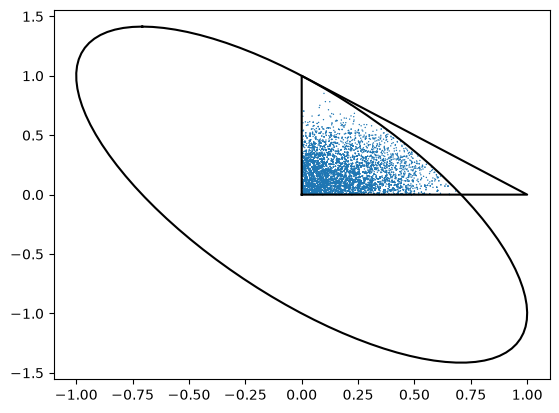

In [8]:
logp = blackjax.mcmc.constraints.constrain(lambda x: -10*jnp.dot(x, x), combined_constraint)

ehr = blackjax.lhr(logp, combined_constraint, 1e0)

state = ehr.init(np.zeros(2))
step = jax.jit(ehr.step)

def one_step(s, k):
    s_new, _ = step(k, s)
    return s_new, s_new

keys = jax.random.split(jax.random.key(42), 10000)
_, states = jax.lax.scan(one_step, state, keys)
x = states.position

plt.plot([0, 0, 1, 0], [0, 1, 0, 0], color='black') # simplex
plt.plot(e[0], e[1], color='black') # ellipsoid

plt.scatter(x[:,0], x[:,1], s=1., edgecolor='none')
plt.show()